# Anaerobic digestion with ADM1, differentiated (`difflow_water.wastewater`)

`anaerobic_digester` is ADM1 as implemented for the Benchmark Simulation Model no. 2 (Rosen & Jeppsson 2006): 19 processes, 24 water-phase states with closed carbon and nitrogen balances, an algebraic pH, and a gas phase. It is solved at steady state (300 days of stiff dynamics from an inoculum, then Newton), so every output has implicit gradients.

1. The report's steady-state verification case.
2. Methane and pH against the hydraulic retention time: the washout cliff.
3. Sensitivities with `jax.grad`, checked against a finite difference.

In [1]:
import time
import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp
import numpy as np
import matplotlib.pyplot as plt

from difflow_water.wastewater.adm1 import (STATES, ADM1Params, adm1_test_influent,
                                           anaerobic_digester)

infl = adm1_test_influent()        # 170 m3/d, 35 C (Rosen & Jeppsson, Section 7)
t = time.time()
r = anaerobic_digester(infl, ADM1Params(gas_flow="uncompensated"))
print(f"converged {bool(r['converged'])} in {time.time() - t:.0f} s")
print(f"pH {float(r['pH']):.10f}   (report 7.4655377698929)")
print(f"S_ac {float(r['S'][STATES.index('S_ac')]):.10f} kg COD/m3   (report 0.1976297169375)")
print(f"methane {float(r['gas_fraction_ch4']) * 100:.1f} % of the gas, {float(r['methane']):.0f} m3/d")

converged True in 10 s
pH 7.4655377699   (report 7.4655377698929)
S_ac 0.1976297169 kg COD/m3   (report 0.1976297169375)
methane 60.9 % of the gas, 1705 m3/d


The report's numbers come back to its printed digits with the *uncompensated* gas flow `k_p (P_gas - P_atm)`. The report's text says BSM2 uses the compensated `k_p (P_gas - P_atm) P_gas / P_atm` (also WaterTAP's), which is the default here; with it the same digester makes slightly more gas:

In [2]:
rc = anaerobic_digester(infl)
print(f"compensated: q_gas {float(rc['q_gas']):.1f} m3/d, pH {float(rc['pH']):.5f};  uncompensated: {float(r['q_gas']):.1f} m3/d")

compensated: q_gas 2808.3 m3/d, pH 7.46656;  uncompensated: 2800.8 m3/d


## Retention time and washout

Shrinking the digester shortens the hydraulic (and, in a CSTR, solids) retention time. Methanogens grow slowly; below a critical retention time they wash out, acids accumulate and the pH collapses. The sweep shows both branches the model can reach.

HRT  20.0 d: pH  7.47, methane  1709.3 m3/d, acetate   0.198 kg COD/m3, converged True
HRT  14.1 d: pH  7.45, methane  1677.0 m3/d, acetate   0.378 kg COD/m3, converged True
HRT  10.0 d: pH  7.41, methane  1612.6 m3/d, acetate   1.069 kg COD/m3, converged True
HRT   7.6 d: pH  7.30, methane  1500.1 m3/d, acetate   2.594 kg COD/m3, converged True
HRT   5.9 d: pH  7.13, methane  1355.9 m3/d, acetate   4.514 kg COD/m3, converged True
HRT   4.7 d: pH  6.89, methane  1196.2 m3/d, acetate   6.417 kg COD/m3, converged True
HRT   3.8 d: pH  5.19, methane    32.6 m3/d, acetate   9.246 kg COD/m3, converged True
HRT   3.2 d: pH  5.19, methane    20.4 m3/d, acetate   9.182 kg COD/m3, converged True
HRT   2.8 d: pH  5.19, methane    15.1 m3/d, acetate   9.124 kg COD/m3, converged True


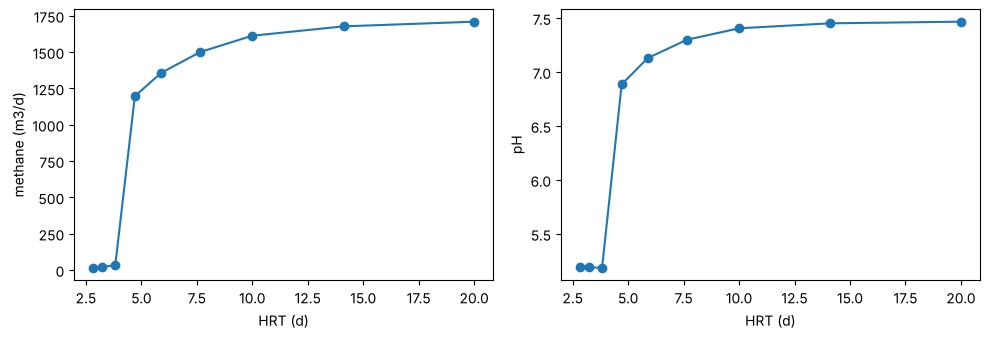

In [3]:
vols = np.array([3400, 2400, 1700, 1300, 1000, 800, 650, 550, 480])
rows = []
for V in vols:
    o = anaerobic_digester(infl, ADM1Params(V_liq=float(V), V_gas=float(V) * 300 / 3400))
    rows.append((V / 170.0, float(o["pH"]), float(o["methane"]), float(o["S"][STATES.index("S_ac")]), bool(o["converged"])))
rows = np.array(rows)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(rows[:, 0], rows[:, 2], "o-"); ax[0].set_xlabel("HRT (d)"); ax[0].set_ylabel("methane (m3/d)")
ax[1].plot(rows[:, 0], rows[:, 1], "o-"); ax[1].set_xlabel("HRT (d)"); ax[1].set_ylabel("pH")
fig.tight_layout()
for hrt, ph, ch4, ac, ok in rows:
    print(f"HRT {hrt:5.1f} d: pH {ph:5.2f}, methane {ch4:7.1f} m3/d, acetate {ac:7.3f} kg COD/m3, converged {bool(ok)}")

## Sensitivities

Methane production with respect to the operating temperature (through the temperature-dependent constants only: the biochemical rates in this model are at 35 C, see the report) and to the disintegration and acetoclastic uptake rates, at the base digester. Reverse mode, checked against a central difference.

In [4]:
def methane(x):
    p = ADM1Params(T_op=x[0], k_dis=x[1], k_m_ac=x[2])
    return anaerobic_digester(infl, p)["methane"]

x0 = jnp.array([308.15, 0.5, 8.0])
g = np.asarray(jax.grad(methane)(x0))
for i, name in enumerate(["T_op (K)", "k_dis (1/d)", "k_m_ac (1/d)"]):
    h = 1e-3 * float(x0[i])
    e = jnp.zeros(3).at[i].set(h)
    fd = float((methane(x0 + e) - methane(x0 - e)) / (2 * h))
    print(f"d methane / d {name:13s} = {g[i]:+.5e}   central difference {fd:+.5e}")
m0 = float(methane(x0))
print("elasticities (relative change in methane per relative change in the parameter):",
      {n: round(float(g[i] * x0[i] / m0), 4) for i, n in enumerate(["T_op", "k_dis", "k_m_ac"])})

d methane / d T_op (K)      = +3.64811e+00   central difference +3.64693e+00


d methane / d k_dis (1/d)   = +2.08492e+01   central difference +2.08493e+01


d methane / d k_m_ac (1/d)  = +3.28684e+00   central difference +3.28686e+00


elasticities (relative change in methane per relative change in the parameter): {'T_op': 0.6577, 'k_dis': 0.0061, 'k_m_ac': 0.0154}


Per kelvin, methane rises by about 3.6 m3/d (0.2 % per K), here only through the temperature-dependent gas solubilities and acid-base constants. The rates barely matter at a 20-day retention time: a 1 % change in the acetoclastic uptake rate moves methane by 0.015 %, in the disintegration rate by 0.006 %. Near the washout cliff (between 4.7 and 3.8 days above) the same derivatives grow by orders of magnitude.

## Limits

- Steady state only; the BSM2 dynamic influent is not reproduced.
- The biochemical parameters are the report's 35 C values; only the physico-chemical constants follow `T_op`.
- No ASM1-to-ADM1 interface: the digester takes an ADM1 stream.